# Experiment 9: Differential Evolution (DE)
**Aim:** To implement a simple Differential Evolution algorithm for solving an optimization problem using Python.

**Theory (DE/rand/1/bin):** for each target vector xᵢ
1. **Mutation:** v = x_r1 + F·(x_r2 − x_r3)  (r1, r2, r3 distinct and ≠ i)
2. **Crossover:** build trial u by taking each gene from v with probability CR (at least one gene forced from v)
3. **Selection:** keep u if f(u) ≤ f(xᵢ), else keep xᵢ

**Problem:** Minimise the 2-D Ackley function (global minimum 0 at (0, 0)).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
np.random.seed(0)

def ackley(x):
    x = np.asarray(x); n = len(x)
    return (-20 * np.exp(-0.2 * np.sqrt(np.sum(x ** 2) / n))
            - np.exp(np.sum(np.cos(2 * np.pi * x)) / n) + 20 + np.e)

def differential_evolution(func, dim=2, bounds=(-5, 5), NP=30, F=0.8, CR=0.9, gens=100):
    lo, hi = bounds
    pop = np.random.uniform(lo, hi, (NP, dim))
    fit = np.array([func(p) for p in pop])
    best_hist, snaps = [fit.min()], {0: pop.copy()}
    for g in range(1, gens + 1):
        for i in range(NP):
            r1, r2, r3 = np.random.choice([j for j in range(NP) if j != i], 3, replace=False)
            mutant = np.clip(pop[r1] + F * (pop[r2] - pop[r3]), lo, hi)
            cross = np.random.rand(dim) < CR
            cross[np.random.randint(dim)] = True
            trial = np.where(cross, mutant, pop[i])
            f_trial = func(trial)
            if f_trial <= fit[i]:
                pop[i], fit[i] = trial, f_trial
        best_hist.append(fit.min())
        if g in (5, 15, gens): snaps[g] = pop.copy()
    k = fit.argmin()
    return pop[k], fit[k], best_hist, snaps

best_x, best_f, hist, snaps = differential_evolution(ackley)
print("Best solution:", np.round(best_x, 6))
print("Best value   :", best_f)

Best solution: [-0.  0.]
Best value   : 3.229740919152846e-10


## Convergence curve

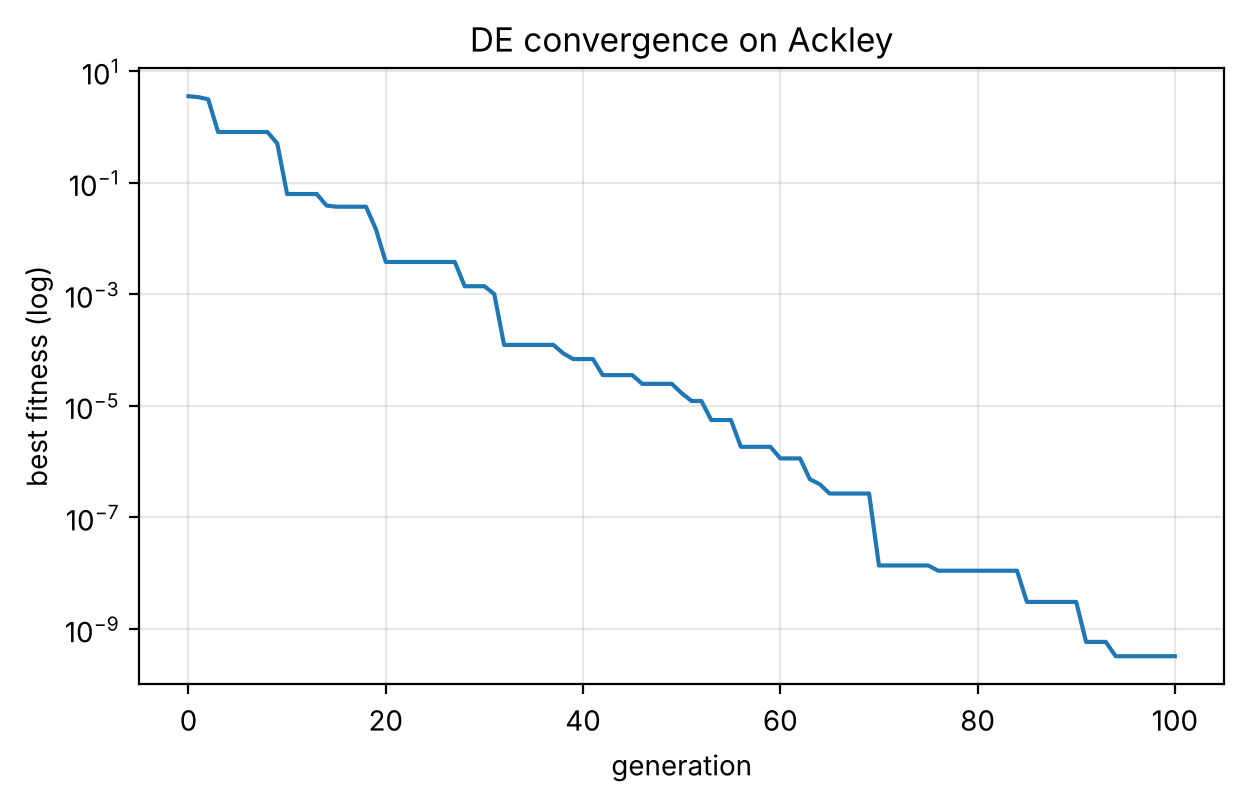

In [2]:
plt.figure(figsize=(7, 4))
plt.plot(hist); plt.yscale("log")
plt.xlabel("generation"); plt.ylabel("best fitness (log)")
plt.title("DE convergence on Ackley"); plt.grid(alpha=0.3); plt.show()

## Population evolution

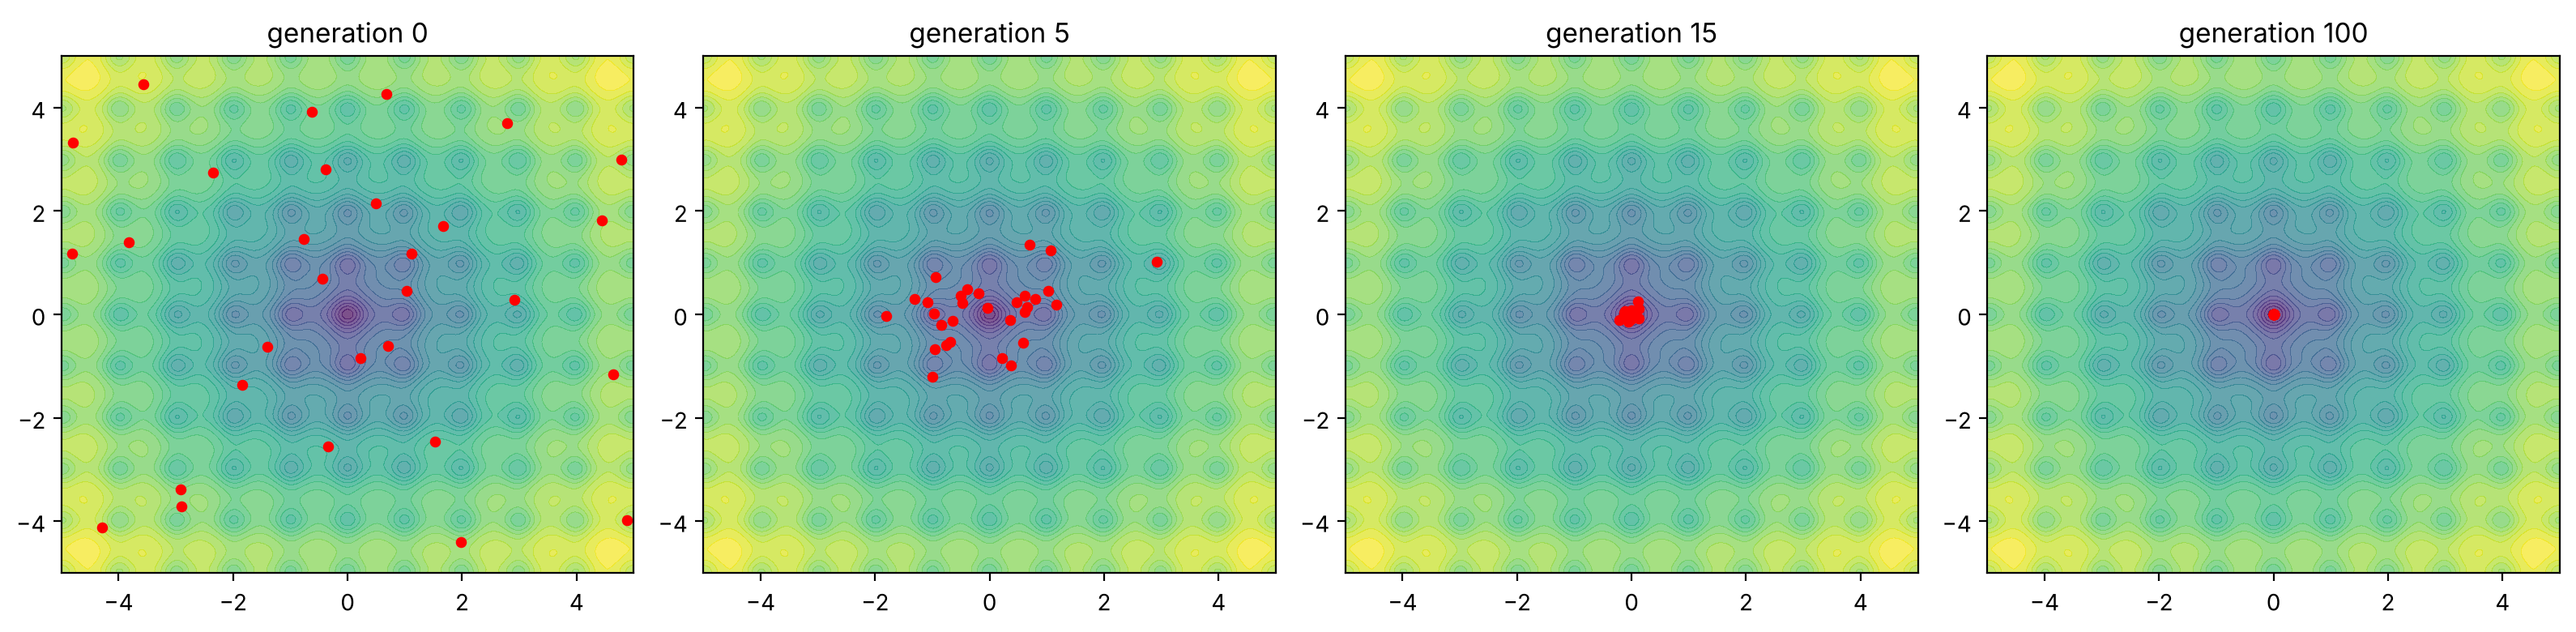

In [3]:
X, Y = np.meshgrid(np.linspace(-5, 5, 300), np.linspace(-5, 5, 300))
Z = (-20 * np.exp(-0.2 * np.sqrt((X ** 2 + Y ** 2) / 2))
     - np.exp((np.cos(2 * np.pi * X) + np.cos(2 * np.pi * Y)) / 2) + 20 + np.e)
fig, axes = plt.subplots(1, len(snaps), figsize=(4 * len(snaps), 4))
for ax, (g, pos) in zip(axes, snaps.items()):
    ax.contourf(X, Y, Z, 30, cmap="viridis", alpha=0.7)
    ax.scatter(pos[:, 0], pos[:, 1], c="red", s=15)
    ax.set_title(f"generation {g}")
plt.tight_layout(); plt.show()

## Effect of the scale factor F and crossover rate CR

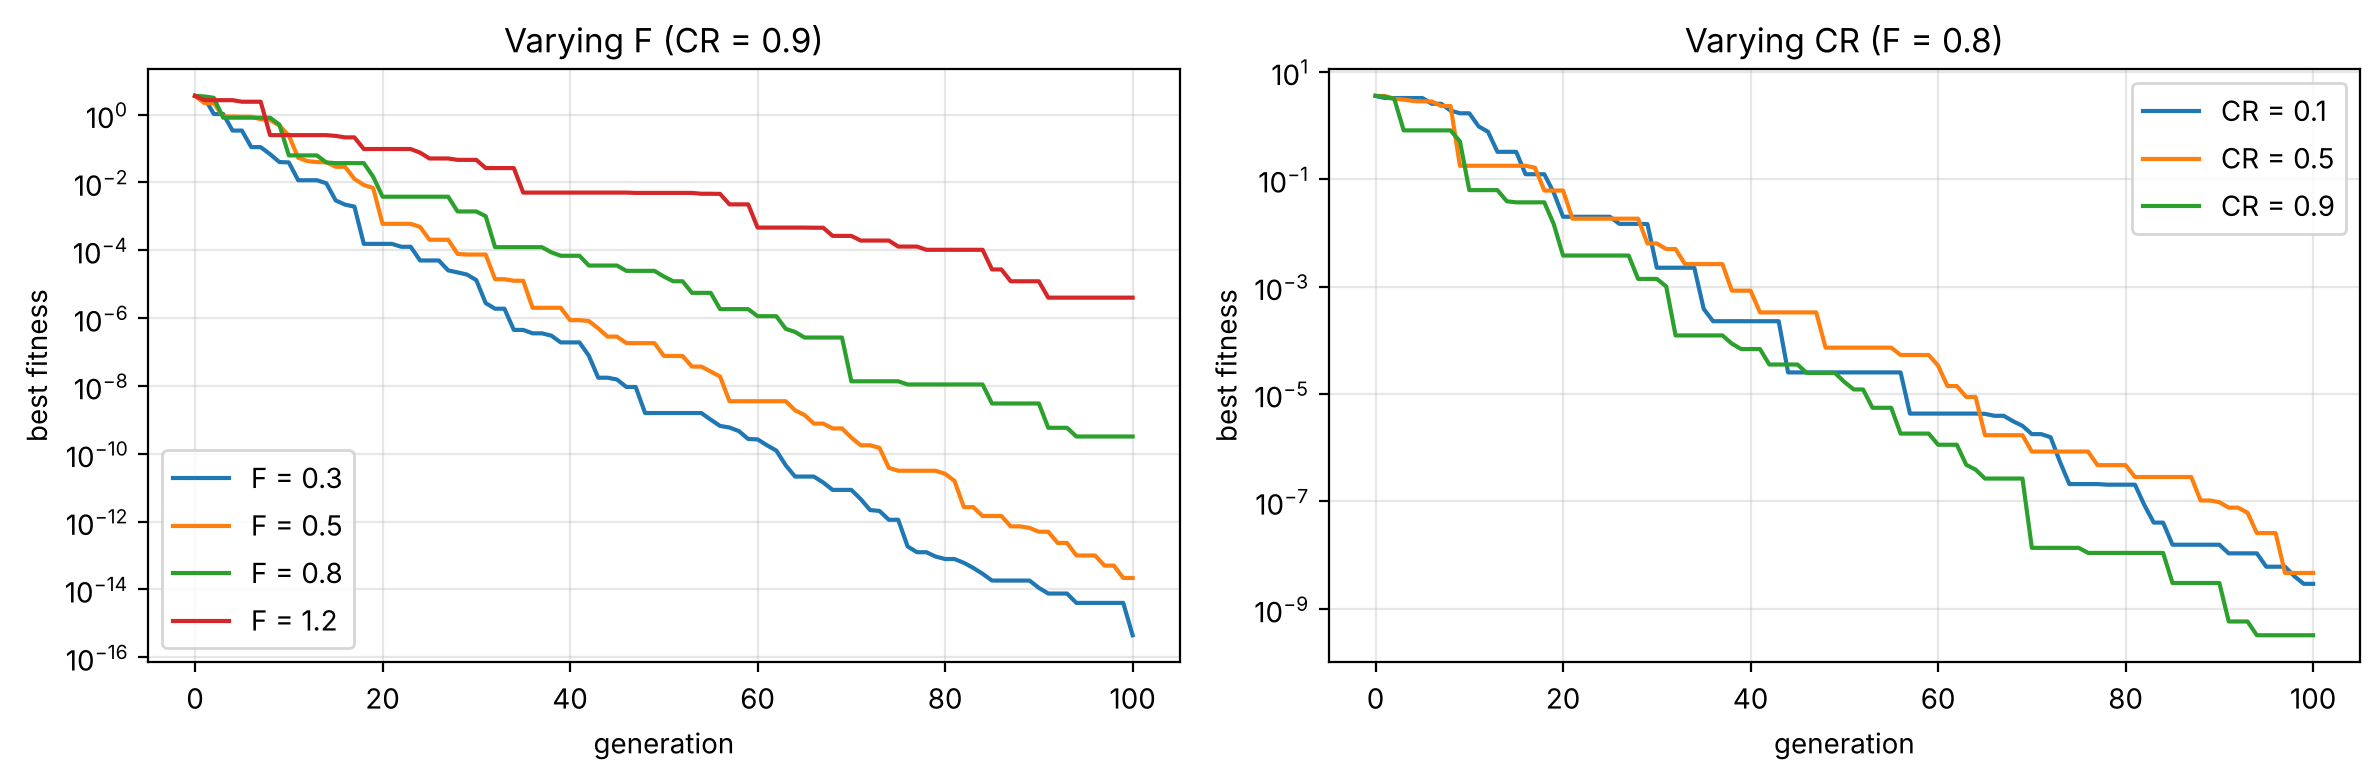

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for F in [0.3, 0.5, 0.8, 1.2]:
    np.random.seed(0)
    h = differential_evolution(ackley, F=F)[2]
    ax[0].plot(h, label=f"F = {F}")
ax[0].set_title("Varying F (CR = 0.9)")
for CR in [0.1, 0.5, 0.9]:
    np.random.seed(0)
    h = differential_evolution(ackley, CR=CR)[2]
    ax[1].plot(h, label=f"CR = {CR}")
ax[1].set_title("Varying CR (F = 0.8)")
for a in ax:
    a.set_yscale("log"); a.set_xlabel("generation"); a.set_ylabel("best fitness"); a.legend(); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## Conclusion
DE/rand/1/bin converged to the global minimum of the Ackley function. Differences between population members drive the search, so step sizes shrink automatically as the population converges. F controls the mutation step size and CR the amount of gene mixing.